# PCA, LDA and RBF kernel PCA

UCI Wine has 178 samples, 13 chemical measurements and three cultivars. This lab
uses the offline scikit-learn copy and retains labels 1–3. The stratified 70/30
split uses seed 0. Scaling, PCA, LDA and classifiers below fit only training data.
Five-fold CV later refits every transform inside each training fold. Models and
two-component projections are fixed in advance; the test partition is not tuned.

The moons/circles KPCA plots fit their full synthetic datasets for exploratory
visualisation only. They do not measure held-out classification performance.
Custom PCA/LDA remain explicit matrix calculations. LDA now uses count-weighted
scatter; KPCA now uses sqrt-eigenvalue scaling and has one definition.


In [1]:
# UCI Wine: packaged scikit-learn copy, no network/download dependency.
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine.insert(0, 'Class label', wine.target + 1)
X, y = wine.data, wine.target + 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0,
)
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)
assert len(X_train) == 124 and len(X_test) == 54
print('Wine features:', wine.feature_names)
print('Training/test samples:', len(X_train), len(X_test))

Wine features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Training/test samples: 124 54


In [2]:
# Step 1.2: Implement PCA from Scratch

import numpy as np

# Compute covariance matrix
cov_mat = np.cov(X_train_std.T)

# Perform eigendecomposition
eigen_vals, eigen_vecs = np.linalg.eigh(cov_mat)

# Sort eigenvalues in descending order
eigen_pairs = [(np.abs(eigen_vals[i]), eigen_vecs[:, i]) for i in range(len(eigen_vals))]
eigen_pairs.sort(key=lambda k: k[0], reverse=True)

# Create projection matrix (top 2 components)
w = np.hstack((eigen_pairs[0][1][:, np.newaxis],
               eigen_pairs[1][1][:, np.newaxis]))

# Transform training data
X_train_pca = X_train_std.dot(w)
pca_components_custom = w.copy()

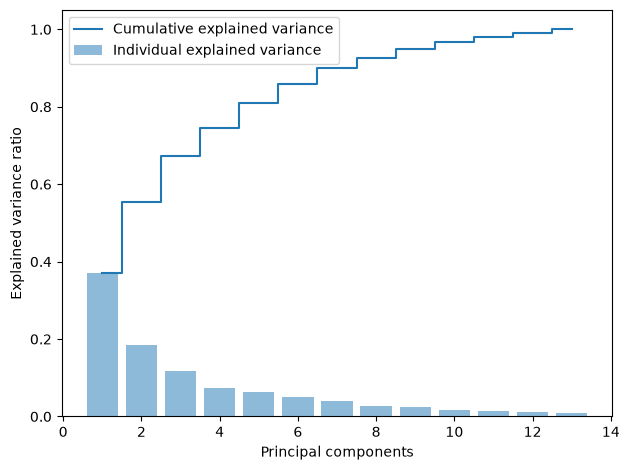

In [3]:
# Step 1.3: Visualize Explained Variance

import matplotlib.pyplot as plt

# Calculate explained variance ratios
tot = sum(eigen_vals)
var_exp = [(i / tot) for i in sorted(eigen_vals, reverse=True)]
cum_var_exp = np.cumsum(var_exp)

# Plot
plt.bar(range(1, len(var_exp) + 1), var_exp, alpha=0.5, align='center',
        label='Individual explained variance')
plt.step(range(1, len(cum_var_exp) + 1), cum_var_exp, where='mid',
         label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal components')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [4]:
# Step 1.4: PCA with scikit-learn

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca_sk = pca.fit_transform(X_train_std)
X_test_pca_sk = pca.transform(X_test_std)


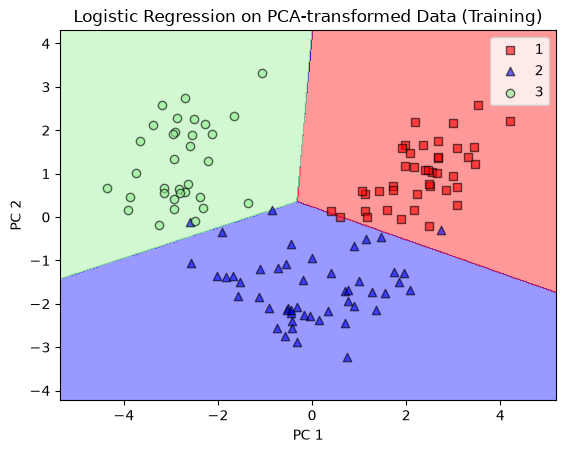

Test Accuracy: 0.926


In [5]:
# Step 1.5: Classification and Visualization

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

lr = OneVsRestClassifier(LogisticRegression(random_state=1, solver='lbfgs', max_iter=1000))
lr.fit(X_train_pca_sk, y_train)

# Helper function to plot decision regions (from the book)
from matplotlib.colors import ListedColormap
def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', '^', 'o', 'v', 'D')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])
    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
    # plot class samples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], 
                    y=X[y == cl, 1],
                    alpha=0.6, 
                    color=cmap(idx),
                    edgecolor='black',
                    marker=markers[idx], 
                    label=cl)
    plt.xlabel('PC 1')
    plt.ylabel('PC 2')
    plt.legend(loc='best')

# Plot decision regions for training set
plot_decision_regions(X_train_pca_sk, y_train, classifier=lr)
plt.title('Logistic Regression on PCA-transformed Data (Training)')
plt.show()

# Check accuracy on test set
print('Test Accuracy: %.3f' % lr.score(X_test_pca_sk, y_test))

In [6]:
# Unnormalised scatter: each class contributes according to its sample count.
# The previous sum of class covariance matrices weighted unequal classes equally.
classes = np.unique(y_train)
mean_vecs = [X_train_std[y_train == label].mean(axis=0) for label in classes]
d = X_train_std.shape[1]
S_W = np.zeros((d, d))
S_B = np.zeros((d, d))
mean_overall = X_train_std.mean(axis=0)
for label, mean in zip(classes, mean_vecs):
    class_rows = X_train_std[y_train == label]
    centered = class_rows - mean
    S_W += centered.T @ centered
    difference = (mean - mean_overall).reshape(-1, 1)
    S_B += len(class_rows) * difference @ difference.T

In [7]:
# Solve a symmetric generalised eigenproblem; do not explicitly invert S_W.
from scipy.linalg import eigh

eigen_vals_lda, eigen_vecs_lda = eigh(S_B, S_W)
w = eigen_vecs_lda[:, np.argsort(eigen_vals_lda)[::-1][:2]]
lda_components_custom = w.copy()
X_train_lda = X_train_std @ w

In [8]:
# Step 2.3: LDA with scikit-learn

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

lda = LDA(n_components=2)
X_train_lda_sk = lda.fit_transform(X_train_std, y_train)
X_test_lda_sk = lda.transform(X_test_std)


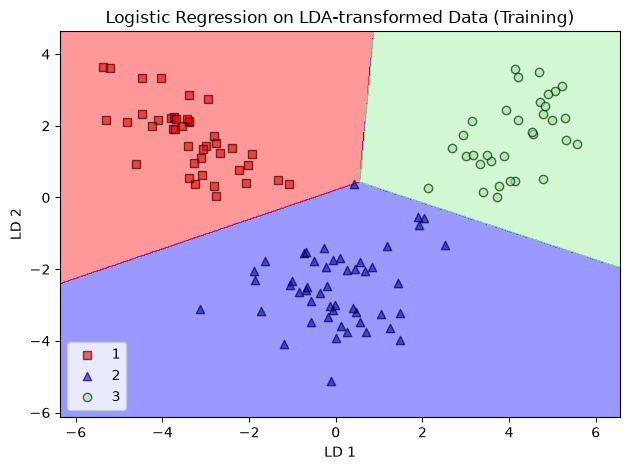

Test Accuracy: 1.000


In [9]:
# Step 2.4: Classification and Visualization

lr = OneVsRestClassifier(LogisticRegression(random_state=1, solver='lbfgs', max_iter=1000))
lr.fit(X_train_lda_sk, y_train)

plot_decision_regions(X_train_lda_sk, y_train, classifier=lr)
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.title('Logistic Regression on LDA-transformed Data (Training)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

print('Test Accuracy: %.3f' % lr.score(X_test_lda_sk, y_test))

In [10]:
# From-scratch RBF KPCA. Scaling by sqrt(eigenvalue) matches sklearn's convention.
from scipy.spatial.distance import pdist, squareform
from scipy.linalg import eigh


def rbf_kernel_pca(X, gamma, n_components):
    K = np.exp(-gamma * squareform(pdist(X, 'sqeuclidean')))
    K = K - K.mean(axis=0)[None, :] - K.mean(axis=1)[:, None] + K.mean()
    eigenvalues, eigenvectors = eigh(K)
    positions = np.argsort(eigenvalues)[::-1][:n_components]
    return eigenvectors[:, positions] * np.sqrt(np.maximum(eigenvalues[positions], 0))

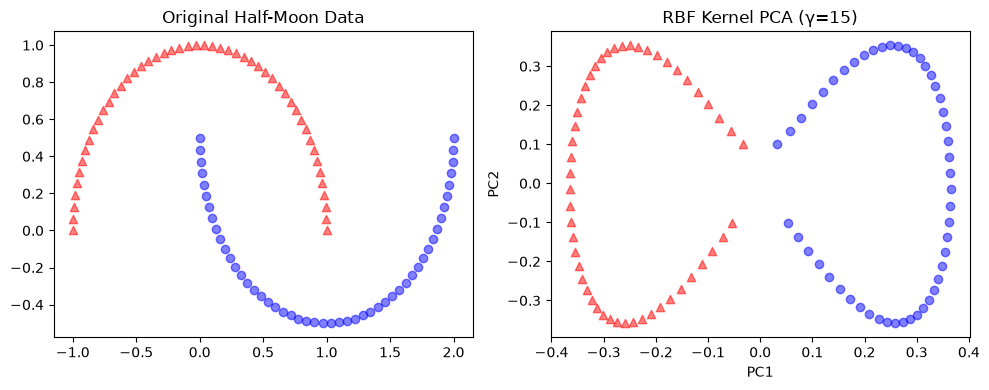

In [11]:
from sklearn.datasets import make_moons

# Generate moons dataset
X, y = make_moons(n_samples=100, random_state=123)

# Apply RBF Kernel PCA
X_kpca = rbf_kernel_pca(X, gamma=15, n_components=2)

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(X[y==0, 0], X[y==0, 1], color='red', marker='^', alpha=0.5)
ax1.scatter(X[y==1, 0], X[y==1, 1], color='blue', marker='o', alpha=0.5)
ax1.set_title('Original Half-Moon Data')

ax2.scatter(X_kpca[y==0, 0], X_kpca[y==0, 1], color='red', marker='^', alpha=0.5)
ax2.scatter(X_kpca[y==1, 0], X_kpca[y==1, 1], color='blue', marker='o', alpha=0.5)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('RBF Kernel PCA (γ=15)')
plt.tight_layout()
plt.show()

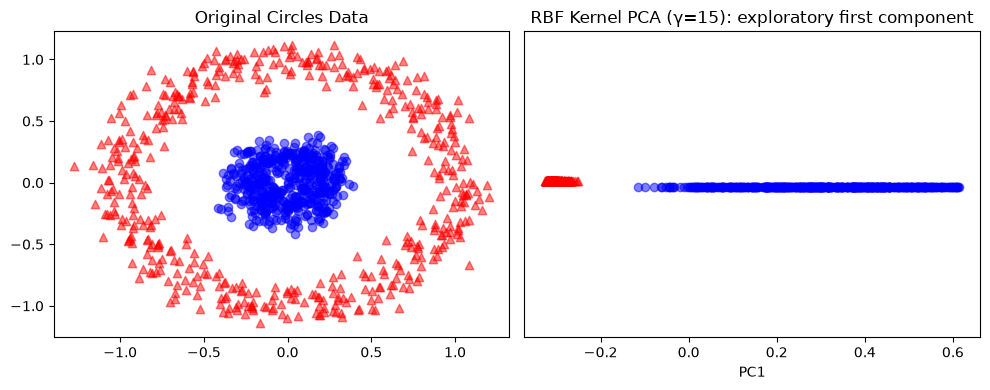

In [12]:
# Step 3.3: Concentric Circles Dataset


from sklearn.datasets import make_circles

X, y = make_circles(n_samples=1000, random_state=123, noise=0.1, factor=0.2)
X_kpca = rbf_kernel_pca(X, gamma=15, n_components=2)

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(X[y==0, 0], X[y==0, 1], color='red', marker='^', alpha=0.5)
ax1.scatter(X[y==1, 0], X[y==1, 1], color='blue', marker='o', alpha=0.5)
ax1.set_title('Original Circles Data')

ax2.scatter(X_kpca[y==0, 0], np.zeros((500,1)) + 0.02, color='red', marker='^', alpha=0.5) # Add slight y-jitter for visualization
ax2.scatter(X_kpca[y==1, 0], np.zeros((500,1)) - 0.02, color='blue', marker='o', alpha=0.5)
ax2.set_ylim([-1, 1])
ax2.set_yticks([])
ax2.set_xlabel('PC1')
ax2.set_title('RBF Kernel PCA (γ=15): exploratory first component')
plt.tight_layout()
plt.show()

In [13]:
# Step 3.4: KPCA with scikit-learn

from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=2, kernel='rbf', gamma=15)
X_kpca_sk = kpca.fit_transform(X)


## Numerical checks and fair evaluation
Eigenvectors have arbitrary signs/scales. Compare PCA/LDA subspaces by principal
angles, and KPCA score Gram matrices (sign independent), rather than raw entries.
LDA uses class labels to seek separation, so it may help classification relative
to PCA's variance objective. This is not a guarantee across datasets. CV fold
standard deviations are descriptive variability, not confidence intervals.

In [14]:
from scipy.linalg import subspace_angles
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
import json
from pathlib import Path

pca_angle = float(np.max(subspace_angles(pca_components_custom, pca.components_.T)))
lda_angle = float(np.max(subspace_angles(lda_components_custom, lda.scalings_[:, :2])))
kpca_gram_error = float(np.max(np.abs(X_kpca @ X_kpca.T - X_kpca_sk @ X_kpca_sk.T)))
assert pca_angle < 1e-8
assert lda_angle < 1e-8
assert kpca_gram_error < 1e-8
np.testing.assert_allclose(sc.mean_, X_train.mean(axis=0), atol=1e-12)

folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(X_train, y_train))
rows = []
for name, projection in [('Original (13 features)', 'passthrough'), ('PCA (2)', PCA(2)), ('LDA (2)', LDA(n_components=2))]:
    model = make_pipeline(
        StandardScaler(), projection,
        OneVsRestClassifier(LogisticRegression(solver='lbfgs', random_state=1, max_iter=1000)),
    )
    scores = cross_val_score(model, X_train, y_train, cv=folds, scoring='accuracy')
    model.fit(X_train, y_train)
    rows.append({'model': name, 'cv_accuracy_mean': float(scores.mean()),
                 'cv_accuracy_std': float(scores.std()),
                 'test_accuracy': float(accuracy_score(y_test, model.predict(X_test)))})
results = {
    'dataset': 'UCI Wine via sklearn.datasets.load_wine', 'seed': 0,
    'train_samples': len(X_train), 'test_samples': len(X_test),
    'feature_names': wine.feature_names, 'cv_folds': 5,
    'checks': {'pca_max_angle_radians': pca_angle, 'lda_max_angle_radians': lda_angle,
               'kpca_max_gram_error': kpca_gram_error},
    'models': rows,
}
Path('results.json').write_text(json.dumps(results, indent=2) + '\n', encoding='utf-8')
print(pd.DataFrame(rows).to_string(index=False))
print('Numerical checks:', results['checks'])

                 model  cv_accuracy_mean  cv_accuracy_std  test_accuracy
Original (13 features)          0.975333         0.033173       1.000000
               PCA (2)          0.959333         0.036539       0.925926
               LDA (2)          0.975667         0.019877       1.000000
Numerical checks: {'pca_max_angle_radians': 1.1592115469745096e-15, 'lda_max_angle_radians': 1.1529511574758651e-15, 'kpca_max_gram_error': 3.941291737419306e-15}


## Interpretation and limitations
The table is a single fixed Wine split plus training-only CV. A small held-out
partition has substantial sampling uncertainty; no universal accuracy or speed
claim follows. The dense KPCA demonstration costs quadratic memory and does not
implement out-of-sample projection. No synthetic gamma setting was tuned on test
data. Figures are exploratory training-data views, not evidence of generalisation.